In [1]:
from config import Config, NetworkKind
from lib import SweepPoint, sweep
from plot import plot_grid_search

results = {}


In [2]:
STEP_SIZE = 4
n_agents = Config().n_agents
seeds = range(100)

results[NetworkKind.RANDOM] = sweep(
    NetworkKind.RANDOM,
    [SweepPoint(p_edge=step / 20) for step in range(1, 21)],
    seeds,
)
plot_grid_search(results[NetworkKind.RANDOM], "p_edge")


KeyboardInterrupt: 

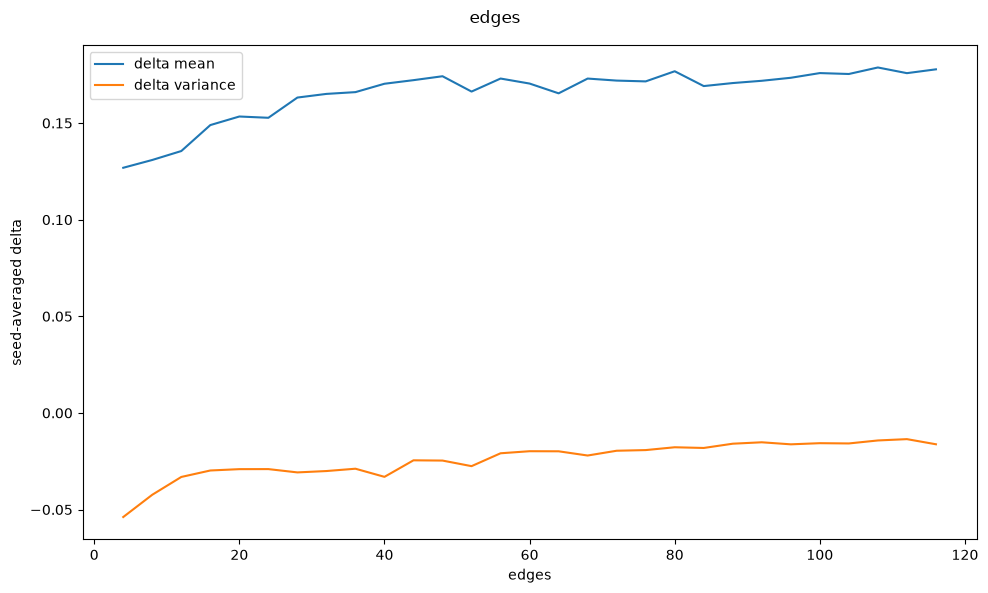

In [ ]:
results[NetworkKind.BARBASI] = sweep(
    NetworkKind.BARBASI,
    [SweepPoint(edges=edges) for edges in range(STEP_SIZE, n_agents, STEP_SIZE)],
    seeds,
)
plot_grid_search(results[NetworkKind.BARBASI], "edges")


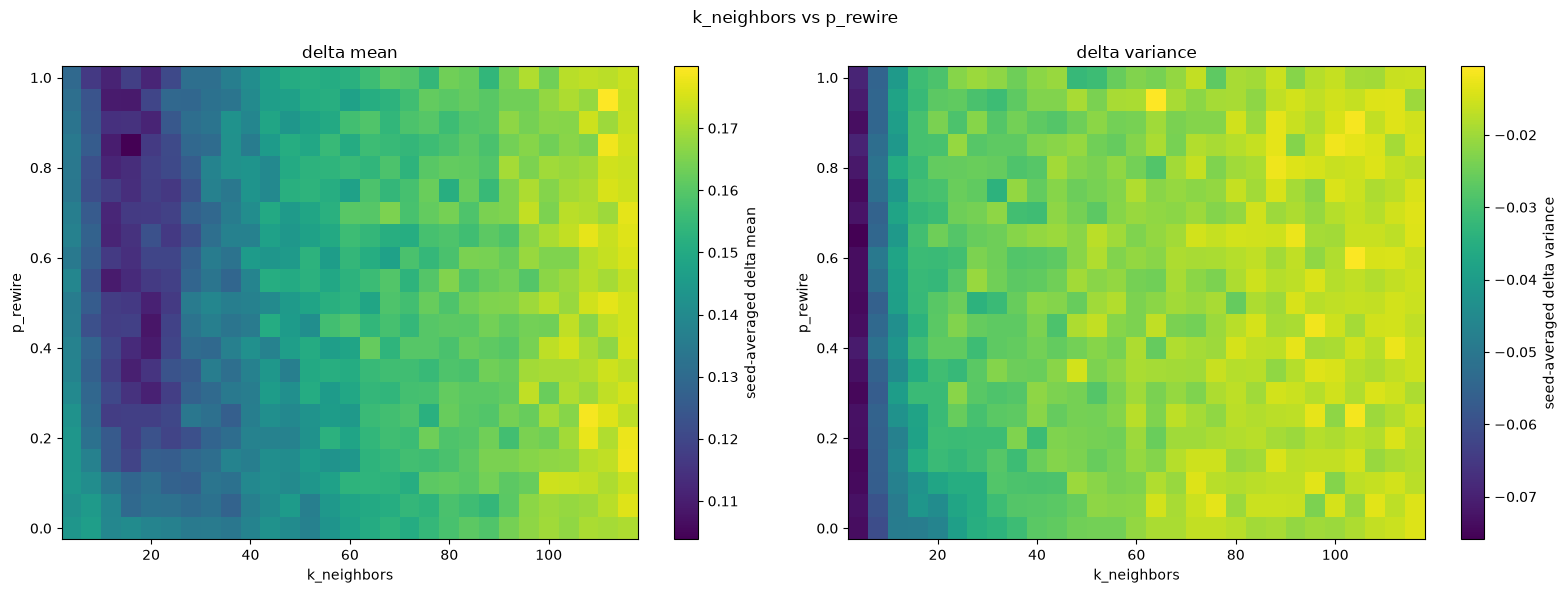

In [ ]:
results[NetworkKind.WATTS] = sweep(
    NetworkKind.WATTS,
    [
        SweepPoint(k_neighbors=neighbors, p_rewire=step / 20)
        for neighbors in range(STEP_SIZE, n_agents, STEP_SIZE)
        for step in range(21)
    ],
    seeds,
)
plot_grid_search(results[NetworkKind.WATTS], "k_neighbors", "p_rewire")


In [ ]:
for kind, summary in results.items():
    print(kind)
    print(summary)


random
SweepResult(highest_delta_mean=0.17782741881949587, average_delta_mean=0.15071623787537652, variance_delta_mean=0.00037702022207571805, average_delta_variance=-0.025680426583677817, seed_means=[0.1985844905836274, 0.1445209329083607, 0.173101137716333, 0.16012318532149855, 0.1928246790079127, 0.13796242982887758, 0.14566817776070623, 0.2043423599039354, 0.18567455174017894, 0.19482919324359876, 0.10348223880001486, 0.14760352534753124, 0.1735311465431622, 0.19501621945684486, 0.1333861022331117, 0.12749278134620273, 0.1686299768056693, 0.11380797410060986, 0.12196250141408785, 0.11739771236400212, 0.16304762975504952, 0.11704513672184161, 0.10794237025457021, 0.16171392608034466, 0.16233513256967255, 0.16514661813340467, 0.07804295417920527, 0.14980957449084814, 0.1684597016052824, 0.12315158695618775, 0.20075875192123666, 0.18286320168062548, 0.17061217405547585, 0.17385997686671306, 0.13648727468999422, 0.06937848818893891, 0.11862850573475917, 0.1432659165179821, 0.1576296728

In [ ]:
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

random_vs_barbasi = ttest_rel(
    results[NetworkKind.RANDOM].seed_means,
    results[NetworkKind.BARBASI].seed_means,
)
random_vs_watts = ttest_rel(
    results[NetworkKind.RANDOM].seed_means,
    results[NetworkKind.WATTS].seed_means,
)
barbasi_vs_watts = ttest_rel(
    results[NetworkKind.BARBASI].seed_means,
    results[NetworkKind.WATTS].seed_means,
)
adjusted = multipletests(
    [random_vs_barbasi.pvalue, random_vs_watts.pvalue, barbasi_vs_watts.pvalue],
    method="holm",
)[1]
print("random vs barbasi:", random_vs_barbasi, "Holm p:", adjusted[0])
print("random vs watts:", random_vs_watts, "Holm p:", adjusted[1])
print("barbasi vs watts:", barbasi_vs_watts, "Holm p:", adjusted[2])


random vs barbasi: TtestResult(statistic=np.float64(-4.916110320965711), pvalue=np.float64(3.5058242410453808e-06), df=np.int64(99)) Holm p: 7.0116484820907615e-06
random vs watts: TtestResult(statistic=np.float64(1.3115996468170168), pvalue=np.float64(0.19268883671882203), df=np.int64(99)) Holm p: 0.19268883671882203
barbasi vs watts: TtestResult(statistic=np.float64(6.753172645302909), pvalue=np.float64(9.989405356814414e-10), df=np.int64(99)) Holm p: 2.9968216070443244e-09


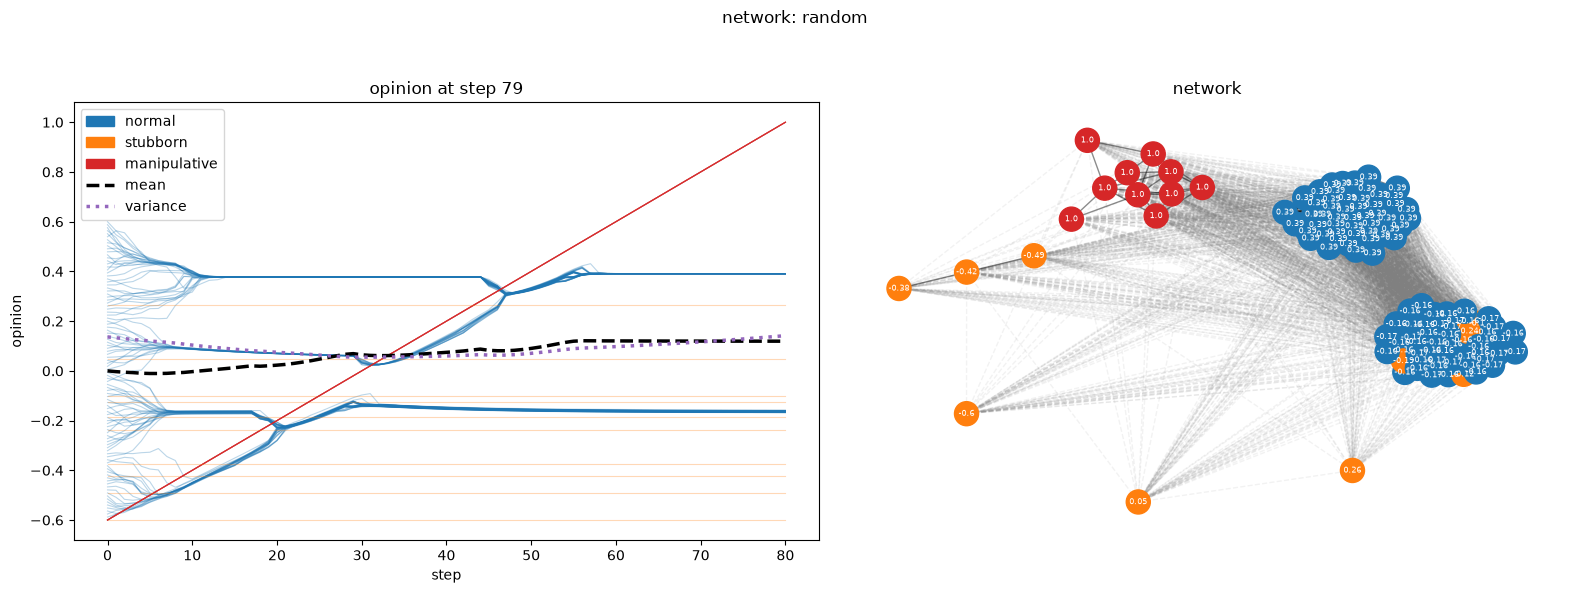

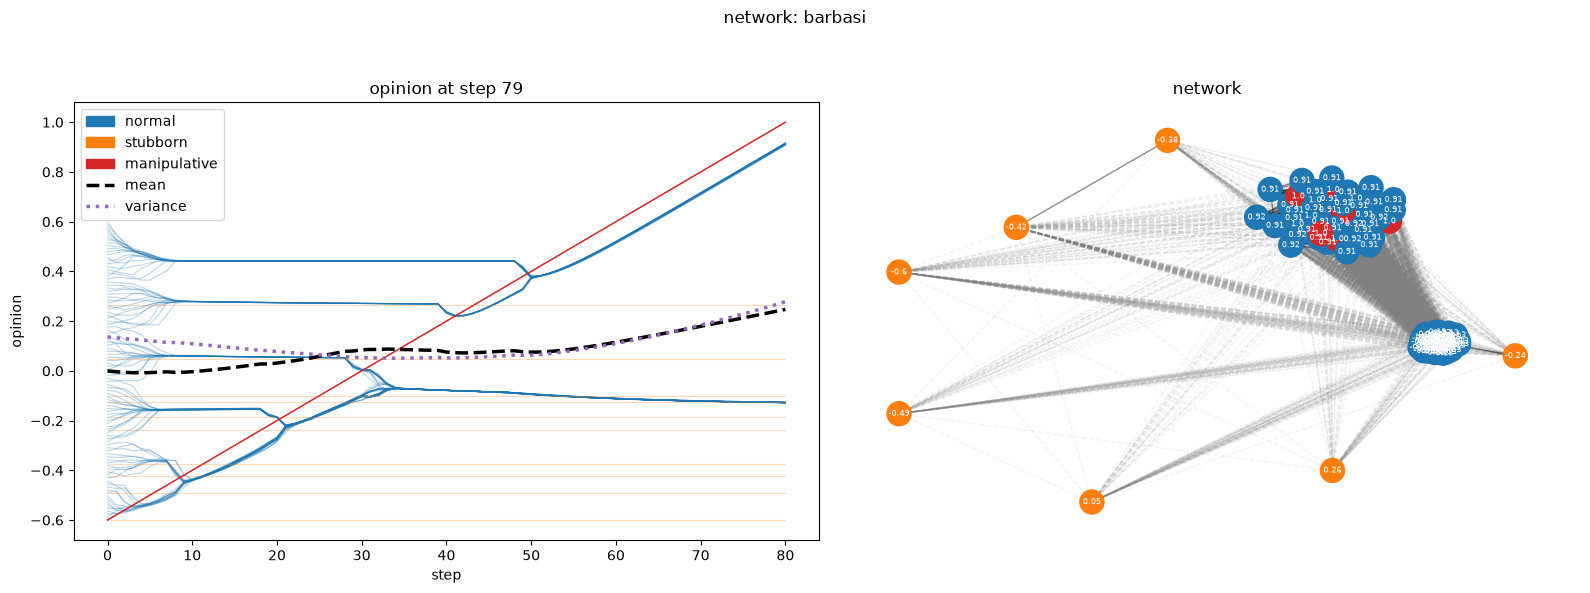

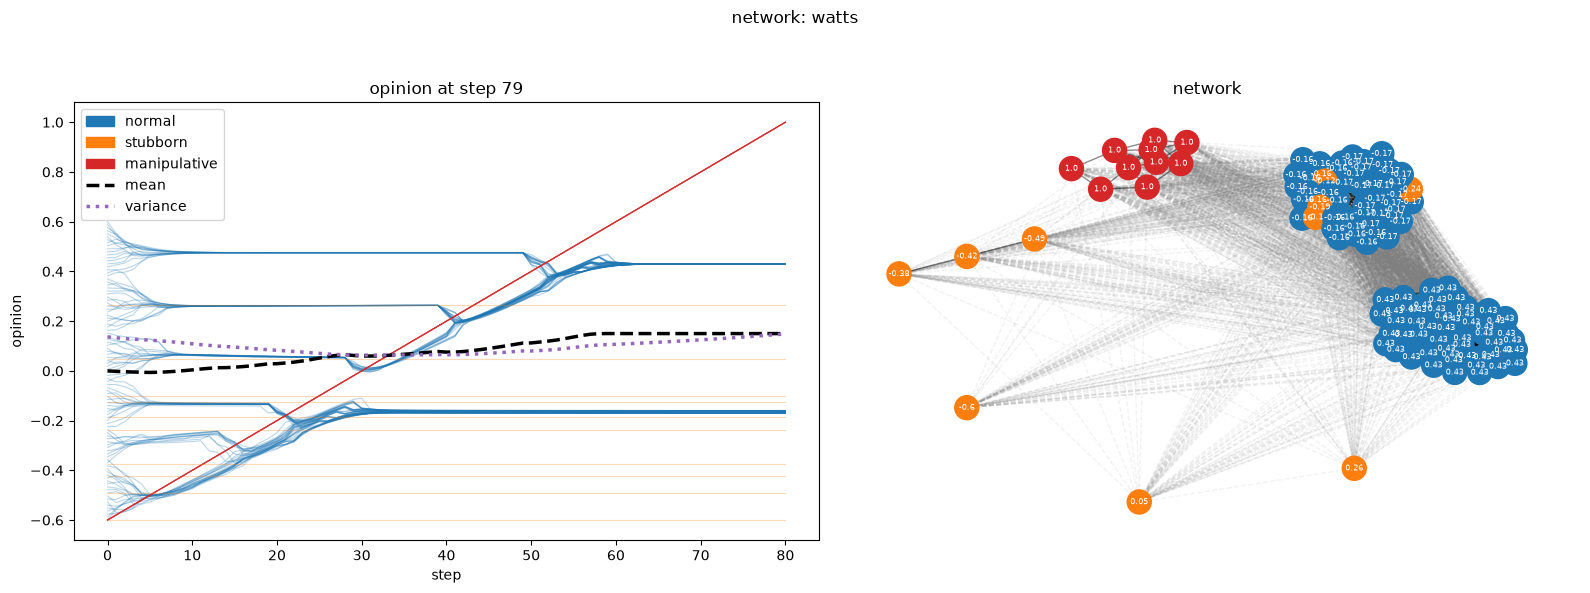

In [3]:
from config import Config
from lib import init_sim, run_one

STEP_SIZE = 4
cfg = Config()
for kind in cfg.networks:
    sim = init_sim(cfg, kind)
    run_one(cfg, sim, True)
